
# LAB 07 - OPEN ENDED LAB
# PROJECT: HEALTH RISK CLASSIFICATION
# ROLL NO: 24F-AI-204


In [ ]:
import os

print(os.listdir())

['.config', '.ipynb_checkpoints', 'archive (1).zip', 'sample_data']


In [ ]:
import zipfile

with zipfile.ZipFile("archive (1).zip", "r") as zip_ref:
    zip_ref.extractall("diabetes_data")

print("ZIP extracted successfully!")

ZIP extracted successfully!


In [ ]:
import os

print(os.listdir("diabetes_data"))

['diabetes.csv']


In [11]:
import pandas as pd

df = pd.read_csv("diabetes_data/diabetes.csv")

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:")
print(df.shape)

Dataset loaded successfully!
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset shape:
(768, 9)


Import Libraries

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


Load Dataset

In [15]:
df = pd.read_csv("diabetes_data/diabetes.csv")

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

Dataset loaded successfully!

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset shape:
(768, 9)


Dataset information

In [16]:
print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.10546

Check missing values

In [17]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Handle invalid values

In [18]:
columns_with_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[columns_with_missing] = df[columns_with_missing].replace(
    0,
    np.nan
)

print("Missing values after replacing invalid zeros:")
print(df.isnull().sum())

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


Fill missing values

In [19]:
for column in columns_with_missing:
    df[column] = df[column].fillna(df[column].median())

print("\nMissing values after preprocessing:")
print(df.isnull().sum())


Missing values after preprocessing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Visualize diabetes outcome

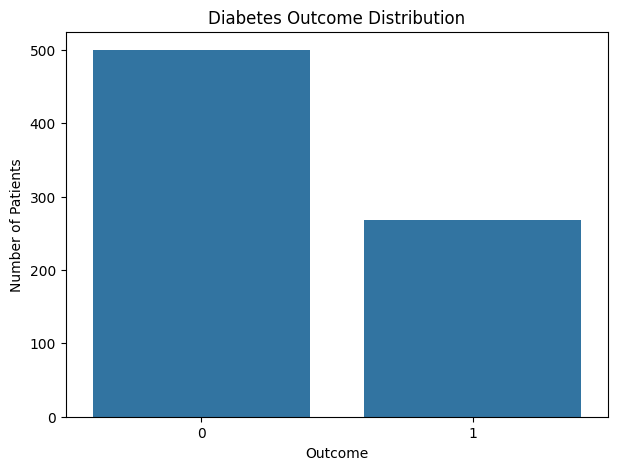

In [20]:
plt.figure(figsize=(7, 5))

sns.countplot(x=df["Outcome"])

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.show()

Correlation heatmap

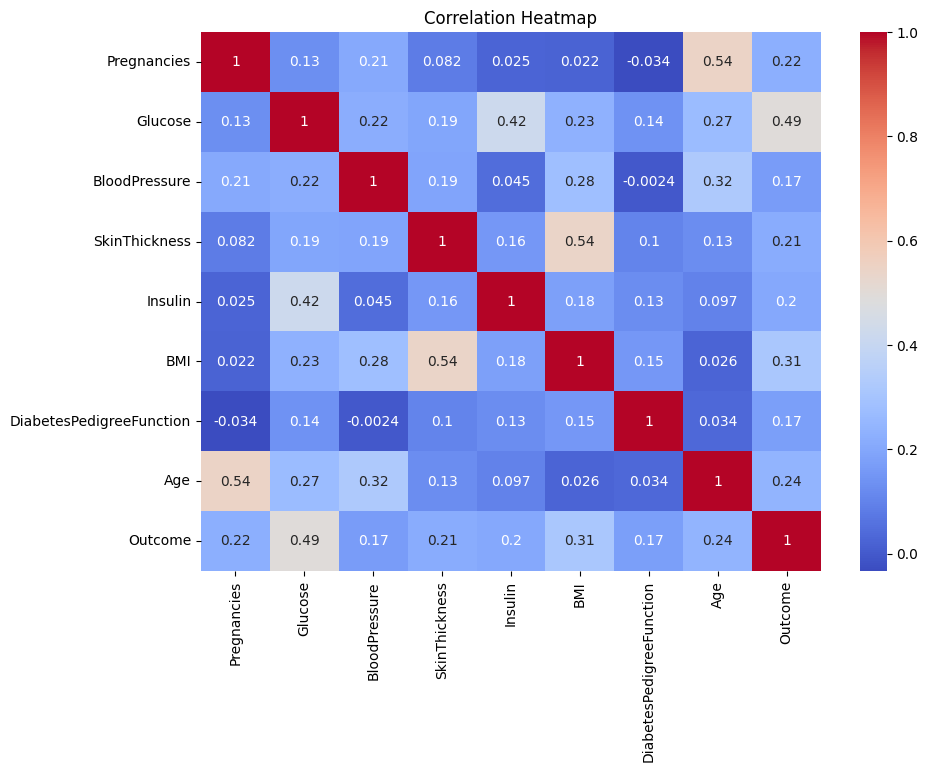

In [21]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

Separate features and target

In [22]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (768, 8)
Target shape: (768,)


Train/test split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


Normalize/standardize data

In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data scaling completed!")

Data scaling completed!


Train SVM model

In [25]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM model trained successfully!")

SVM model trained successfully!


Train Decision Tree

In [26]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

decision_tree_pred = decision_tree_model.predict(X_test)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


Evaluate SVM

In [27]:
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

print("\n===== SVM RESULTS =====")
print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))


===== SVM RESULTS =====
Accuracy: 0.7402597402597403
Precision: 0.6521739130434783
Recall: 0.5555555555555556
F1 Score: 0.6

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



Evaluate Decision Tree

In [28]:
dt_accuracy = accuracy_score(y_test, decision_tree_pred)
dt_precision = precision_score(y_test, decision_tree_pred)
dt_recall = recall_score(y_test, decision_tree_pred)
dt_f1 = f1_score(y_test, decision_tree_pred)

print("\n===== DECISION TREE RESULTS =====")
print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 Score:", dt_f1)

print("\nClassification Report:")
print(classification_report(y_test, decision_tree_pred))


===== DECISION TREE RESULTS =====
Accuracy: 0.6818181818181818
Precision: 0.5531914893617021
Recall: 0.48148148148148145
F1 Score: 0.5148514851485149

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.79      0.76       100
           1       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67      0.68      0.68       154



SVM confusion matrix

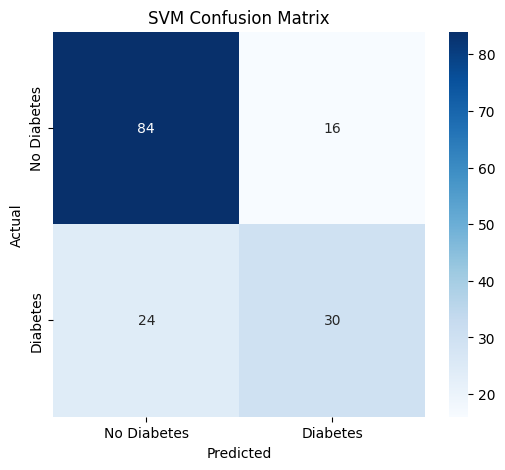

In [29]:
cm_svm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Decision Tree confusion matrix

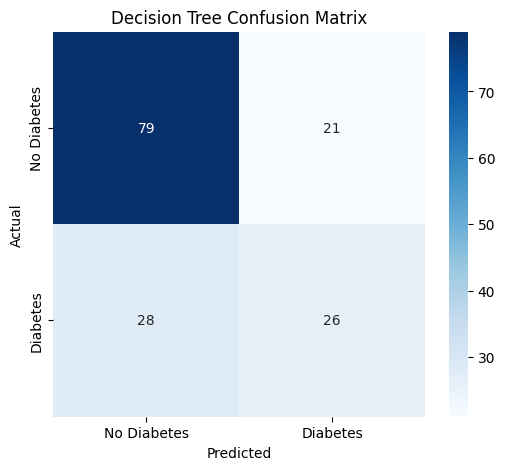

In [30]:
cm_dt = confusion_matrix(y_test, decision_tree_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Compare both models

In [31]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "SVM": [
        svm_accuracy,
        svm_precision,
        svm_recall,
        svm_f1
    ],
    "Decision Tree": [
        dt_accuracy,
        dt_precision,
        dt_recall,
        dt_f1
    ]
})

print("\n===================================")
print("MODEL COMPARISON")
print("===================================")

print(comparison)


MODEL COMPARISON
      Metric       SVM  Decision Tree
0   Accuracy  0.740260       0.681818
1  Precision  0.652174       0.553191
2     Recall  0.555556       0.481481
3   F1 Score  0.600000       0.514851


Comparison graph

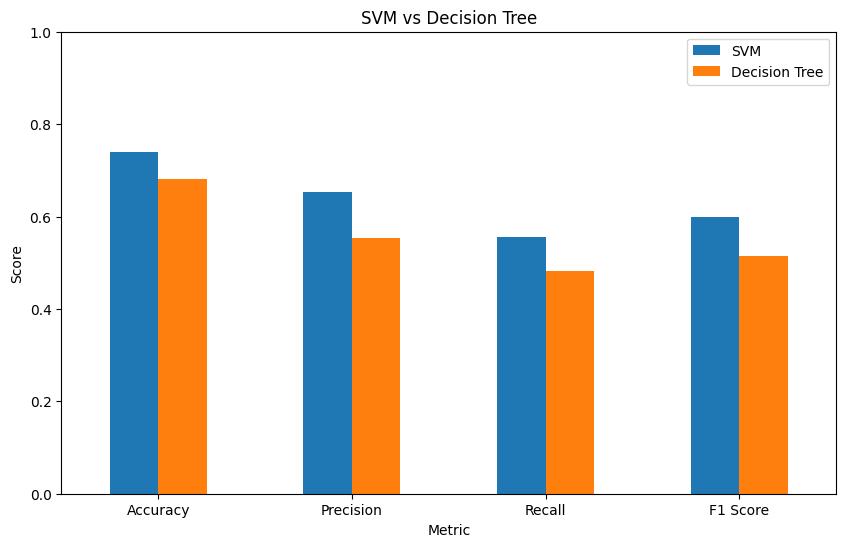

In [32]:
comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("SVM vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()

Disicion Tree Visulation

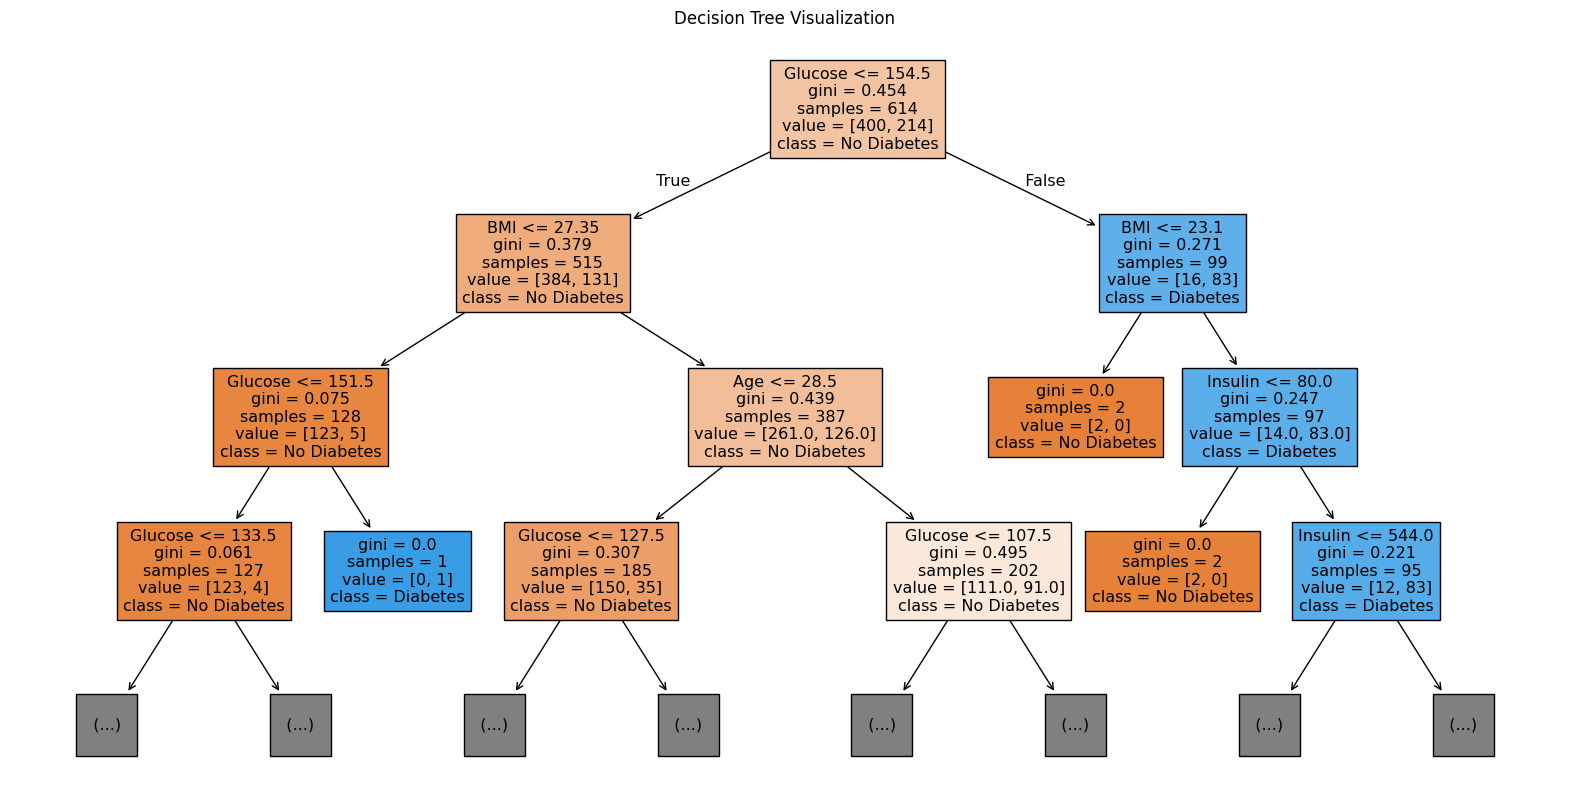

In [33]:
plt.figure(figsize=(20, 10))

plot_tree(
    decision_tree_model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    max_depth=3
)

plt.title("Decision Tree Visualization")

plt.show()

Final comparison

In [36]:
print("\n===================================")
print("FINAL CONCLUSION")
print("===================================")

if svm_accuracy > dt_accuracy:
    print("SVM achieved higher accuracy than Decision Tree.")

elif dt_accuracy > svm_accuracy:
    print("Decision Tree achieved higher accuracy than SVM.")

else:
    print("Both models achieved the same accuracy.")


FINAL CONCLUSION
SVM achieved higher accuracy than Decision Tree.
